In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
def load_image(path):
    img = Image.open(path).convert('RGB')
    return np.array(img, dtype=np.float64)

def show_images(imgs, titles, figsize=(14, 6)):
    n = len(imgs)
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(imgs, titles)):
        plt.subplot(1, n, i + 1)
        plt.imshow(np.clip(im, 0, 255).astype(np.uint8))
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
def nearest_sample(img, xs, ys):
    h, w = img.shape[0], img.shape[1]
    xr = np.round(xs).astype(int)
    yr = np.round(ys).astype(int)
    valid = (xr >= 0) & (xr < w) & (yr >= 0) & (yr < h)
    xr_c = np.clip(xr, 0, w - 1)
    yr_c = np.clip(yr, 0, h - 1)
    out = img[yr_c, xr_c]
    out[~valid] = 0
    return out

In [ ]:
def affine_matrix(angle_deg=0, scale=1.0, tx=0, ty=0, shear=0):
    theta = np.deg2rad(angle_deg)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    R = np.array([[cos_t, -sin_t],
                  [sin_t, cos_t]]) * scale
    Sh = np.array([[1, shear],
                   [0, 1]])
    M2 = R @ Sh
    M = np.array([
        [M2[0, 0], M2[0, 1], tx],
        [M2[1, 0], M2[1, 1], ty],
        [0, 0, 1]
    ])
    return M


In [ ]:
def warp_affine(img, M, out_h, out_w):
    M_inv = np.linalg.inv(M)
    xs, ys = np.meshgrid(np.arange(out_w), np.arange(out_h))
    ones = np.ones_like(xs)
    dst_coords = np.stack([xs, ys, ones], axis=0).reshape(3, -1)
    src_coords = M_inv @ dst_coords
    src_x = src_coords[0].reshape(out_h, out_w)
    src_y = src_coords[1].reshape(out_h, out_w)

    return nearest_sample(img, src_x, src_y)

In [ ]:
img1 = load_image('test1.png')
img2 = load_image('test2.jpg')
h1, w1 = img1.shape[:2]
h2, w2 = img2.shape[:2]

In [ ]:
def centered_affine(h, w, angle_deg, scale, tx, ty, shear=0):
    to_origin = np.array([[1, 0, -w / 2], [0, 1, -h / 2], [0, 0, 1]])
    back = np.array([[1, 0, w / 2], [0, 1, h / 2], [0, 0, 1]])
    core = affine_matrix(angle_deg, scale, tx, ty, shear)
    return back @ core @ to_origin

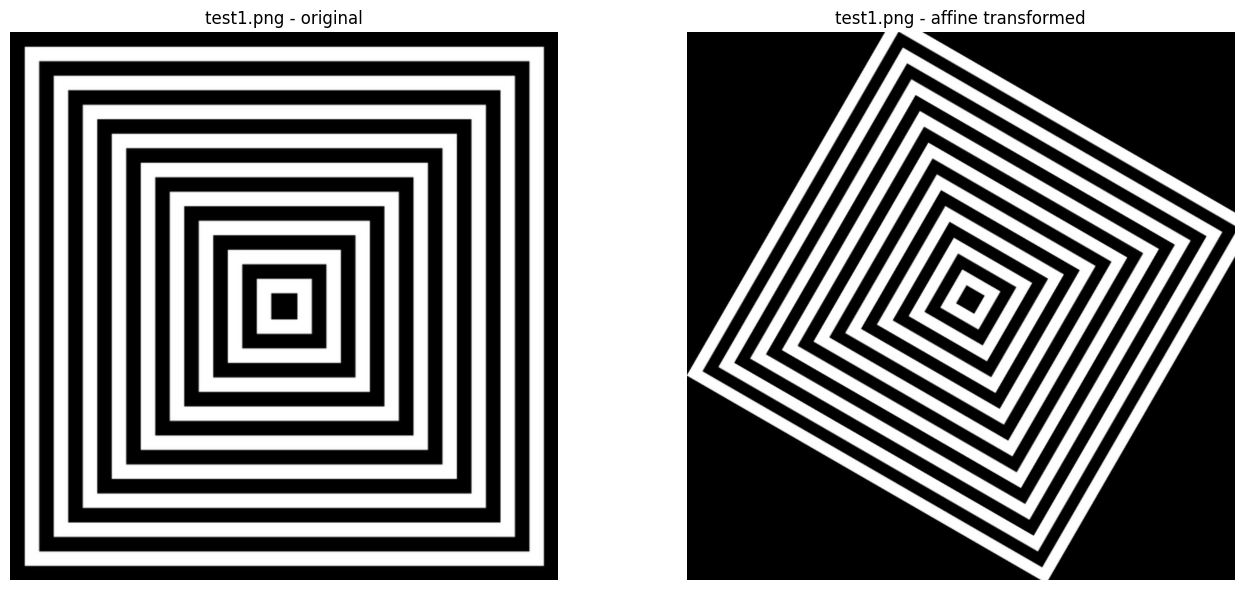

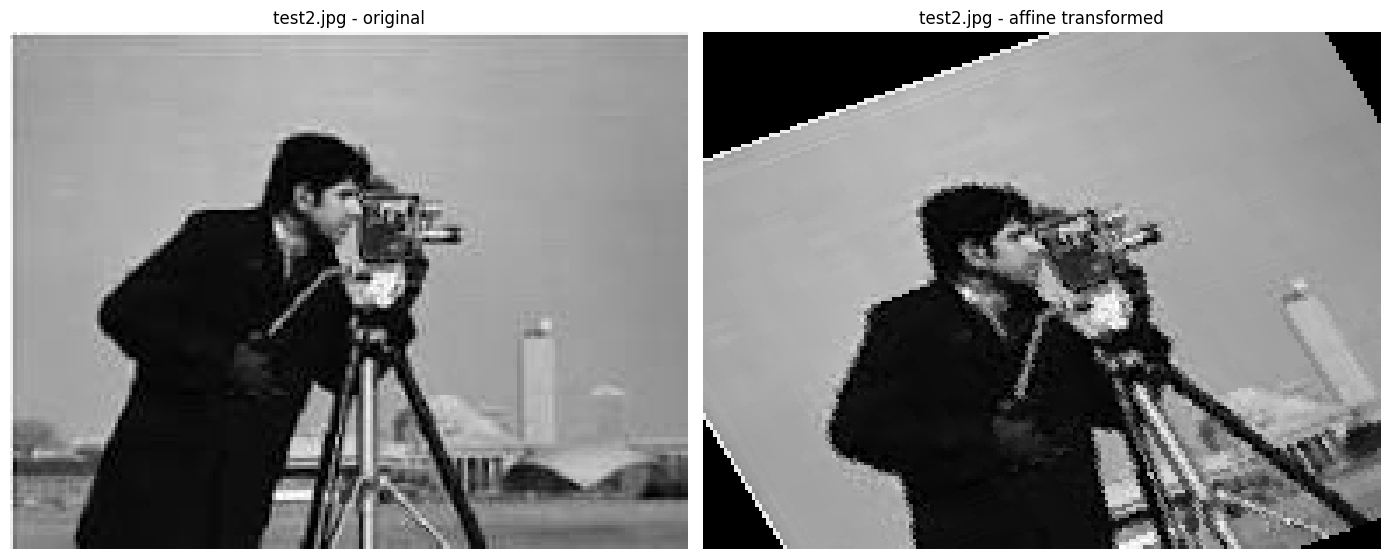

In [ ]:
M1 = centered_affine(h1, w1, angle_deg=30, scale=0.8, tx=20, ty=-15)
M2 = centered_affine(h2, w2, angle_deg=-20, scale=1.1, tx=10, ty=10, shear=0.2)

out1 = warp_affine(img1, M1, h1, w1)
out2 = warp_affine(img2, M2, h2, w2)

show_images([img1, out1], ['test1.png - original', 'test1.png - affine transformed'])
show_images([img2, out2], ['test2.jpg - original', 'test2.jpg - affine transformed'])

### Projective Tranform / Homography

In [ ]:
def compute_homography(src_pts, dst_pts):
    A = []
    for (x, y), (xp, yp) in zip(src_pts, dst_pts):
        A.append([-x, -y, -1, 0, 0, 0, x * xp, y * xp, xp])
        A.append([0, 0, 0, -x, -y, -1, x * yp, y * yp, yp])
    A = np.array(A)

    _, _, Vt = np.linalg.svd(A)
    H = Vt[-1].reshape(3, 3)
    return H / H[2, 2]

In [ ]:
def warp_perspective(img, H, out_h, out_w):
    H_inv = np.linalg.inv(H)

    xs, ys = np.meshgrid(np.arange(out_w), np.arange(out_h))
    ones = np.ones_like(xs)
    dst_coords = np.stack([xs, ys, ones], axis=0).reshape(3, -1).astype(np.float64)

    src_coords = H_inv @ dst_coords
    src_coords /= src_coords[2:3, :]

    src_x = src_coords[0].reshape(out_h, out_w)
    src_y = src_coords[1].reshape(out_h, out_w)

    return nearest_sample(img, src_x, src_y)

In [ ]:
img3 = load_image('test3.png')
h3, w3 = img3.shape[:2]

src_pts = np.array([
    [330, 90],
    [705, 148],
    [615, 600],
    [250, 500],
], dtype=np.float64)

out_w3, out_h3 = 500, 700
dst_pts = np.array([
    [0, 0],
    [out_w3-1, 0],
    [out_w3-1, out_h3-1],
    [0, out_h3-1],
], dtype=np.float64)

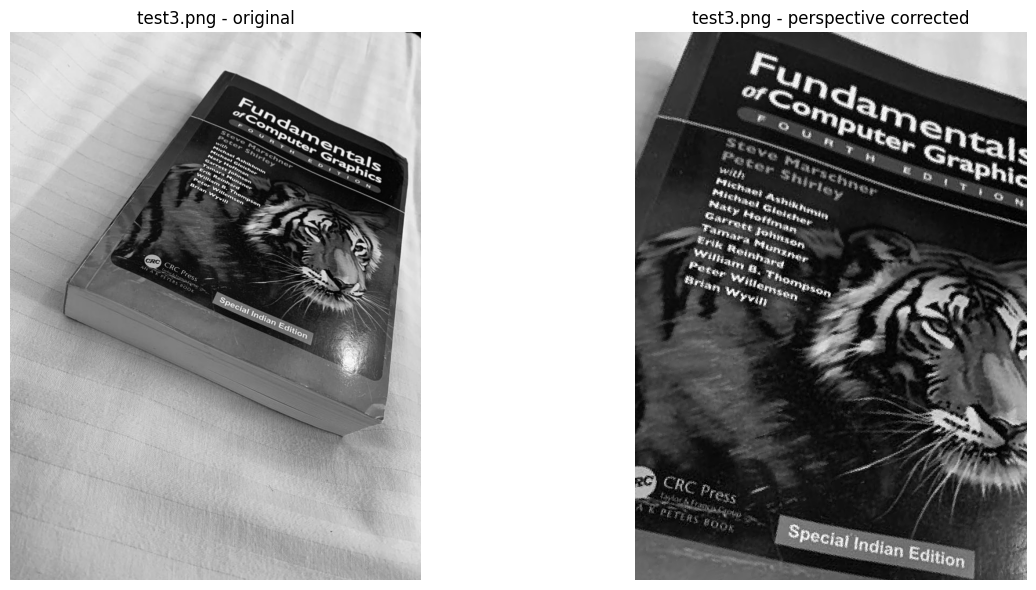

In [ ]:
H = compute_homography(src_pts, dst_pts)
corrected = warp_perspective(img3, H, out_h3, out_w3)
show_images([img3, corrected], ['test3.png - original', 'test3.png - perspective corrected'])